# Training

In [ ]:
!pip install efficientnet_pytorch

In [ ]:
import numpy as np
import pandas as pd
import os
import matplotlib.image as mpimg
import keras as keras

import torch
import torch.nn as nn
import torch.optim as optim 

import torchvision
from torch.utils.data import DataLoader, Dataset
import torch.utils.data as utils
from torchvision import transforms, datasets

import PIL

import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

from efficientnet_pytorch import EfficientNet

In [ ]:
# mount my drive 
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

In [ ]:
%cd gdrive/MyDrive/Colab Notebooks/
# !pwd

In [ ]:
# Calculate class balance TEST

ct_count = !ls ./ct_25_65/test/ct | wc -l
not_ct_count = !ls ./ct_25_65/test/not_ct | wc -l
ct_prop = eval(ct_count[0]) / (eval(ct_count[0]) + eval(not_ct_count[0]))

print(not_ct_count)
print(ct_prop)

In [ ]:
# Load data

def make_weights_for_balanced_classes(images, nclasses):                        
    count = [0] * nclasses                                                      
    for item in images:                                                         
        count[item[1]] += 1                                                     
    weight_per_class = [0.] * nclasses                                      
    N = float(sum(count))                                                   
    for i in range(nclasses):                                                   
        weight_per_class[i] = N/float(count[i])                                 
    weight = [0] * len(images)                                              
    for idx, val in enumerate(images):                                          
        weight[idx] = weight_per_class[val[1]]                                  
    return weight  

params_dict = {
        # Coefficients:   res
        'b0': [224, 224],
        'b1': [240, 240],
        'b2': [260, 260],
        'b3': [300, 300],
        'b4': [380, 380],
        'b5': [456, 456],
        'b6': [528, 528],
        'b7': [600, 600],
        'b8': [672, 672],
        'l2': [800, 800],
    }

def set_loader(optmean, optstd, data_folder, en_model='b1', weighted=True, batch_size=32):
    mean = eval(optmean)
    std = eval(optmean)
    inputsize = params_dict[en_model]

    train_transform = transforms.Compose([
        transforms.Resize(inputsize), #ENb1 input size
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(20),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    val_transform = transforms.Compose([
        transforms.Resize(inputsize), #ENb1 input size
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])
    
    train_dataset = datasets.ImageFolder(root=data_folder+"/train",
                                        transform=train_transform)
    val_dataset = datasets.ImageFolder(root=data_folder+"/val",
                                        transform=val_transform)
    test_dataset = datasets.ImageFolder(root=data_folder+"/test",
                                        transform=val_transform)

    weights = make_weights_for_balanced_classes(train_dataset.imgs, len(train_dataset.classes))                                                                
    weights = torch.DoubleTensor(weights)                                       
    sampler = utils.sampler.WeightedRandomSampler(weights, len(weights))                     

    if weighted:
      train_loader = torch.utils.data.DataLoader(
          train_dataset, batch_size=batch_size, sampler=sampler,
          num_workers=4)
    else:  
      train_loader = torch.utils.data.DataLoader(
          train_dataset, batch_size=batch_size, shuffle=True,
          num_workers=4)
      
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=True, 
        num_workers=4)
    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=batch_size, shuffle=True, 
        num_workers=4)

    return train_loader, val_loader, test_loader

In [ ]:
# Calculate mean/std for normalizing

base_transform = transforms.Compose([
        transforms.Resize(params_dict['b1']), #ENb1 input size
        transforms.ToTensor()])

train_dataset = datasets.ImageFolder(root="./ct_25_65/train", transform=base_transform)

loader = DataLoader(train_dataset,
                         batch_size=32,
                         num_workers=4,
                         shuffle=True)

mean = 0.
std = 0.
for images, _ in loader:
  # print(i)
  batch_samples = images.size(0) # batch size (the last batch can have smaller size!)
  images = images.view(batch_samples, images.size(1), -1)
  mean += images.mean(2).sum(0)
  std += images.std(2).sum(0)

mean /= len(loader.dataset)
std /= len(loader.dataset)

print(mean)
print(std)

In [ ]:
# ct is class 0
train_loader, val_loader, test_loader = set_loader(optmean="(0.5553, 0.5080, 0.4960)", optstd="(0.1844, 0.1982, 0.2017)", data_folder="./ct_25_65", en_model='b5', weighted=False)

In [ ]:
train_loader.dataset.class_to_idx

{'ct': 0, 'not_ct': 1}

In [ ]:
model = EfficientNet.from_pretrained('efficientnet-b5', include_top=True)

# Freeze all
for param in model.parameters():
    param.requires_grad = False

In [ ]:
# replace classification head
model._fc = nn.Sequential(
    # nn.Linear(1280, 512), 
    # nn.Linear(1536, 512), #b3
    nn.Linear(2048, 512), #b5
    # nn.Linear(2560, 512), #b7
    nn.Linear(512, 1))
model.cuda()
model._fc

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): Linear(in_features=512, out_features=1, bias=True)
)

In [ ]:
# inputs = torch.rand(4, 3, 240, 240)
# inputs = inputs.cuda()

# out = model(inputs)
# out.shape

In [ ]:
params_to_update = []
for name,param in model.named_parameters():
    if "_bn" in name:
      param.requires_grad = False
    if param.requires_grad == True:
        params_to_update.append(param)
        print("\t",name)

In [ ]:
def set_optimizer(model, optlr=0.0001, optmomentum=0.9, optweight_decay=1e-4):
    optimizer = optim.SGD(params_to_update,
                          lr=optlr,
                          momentum=optmomentum,
                          weight_decay=optweight_decay)
    return optimizer

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = set_optimizer(model)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, 0.95)

In [ ]:
!pip install tensorboard_logger
%load_ext tensorboard

In [ ]:
from torch.utils.tensorboard import SummaryWriter
# writer = SummaryWriter("runs/b5_weighted")

In [ ]:
child_counter = 0
for child in model.children():
    if child_counter < 2:
        print("child ",child_counter," was frozen")
        for param in child.parameters():
            param.requires_grad = False
    elif child_counter == 2:
        children_of_child_counter = 0
        for children_of_child in child.children():
            if children_of_child_counter < 35:
                for param in children_of_child.parameters():
                    param.requires_grad = False
                print('child ', children_of_child_counter, 'of child',child_counter,' was frozen')
            else:
                for param in children_of_child.parameters():
                      param.requires_grad = True
                print('child ', children_of_child_counter, 'of child',child_counter,' was not frozen')
            children_of_child_counter += 1

    else:
        for param in children_of_child.parameters():
                        param.requires_grad = True
        print("child ",child_counter," was not frozen")
    child_counter += 1

In [ ]:
# Training
PATH = './b5_weighted_best.pt'

print("reg")
best_acc=0
for epoch in range(40,80):  # loop over the dataset multiple times

    running_loss = 0.0
    model.train()
    correct = 0
    total = 0
    for images, labels in train_loader:
        images = images.cuda()
        labels = labels.cuda()
        out = model(images)
        labels = labels.unsqueeze(1).float()
        loss = criterion(out, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        
#         _, predicted = torch.max(out.data, 1)
        total += labels.size(0)
        out = torch.sigmoid(out)
        correct += ((out > 0.5).int() == labels).sum().item()
    
    writer.add_scalar("Loss/train", running_loss/total, epoch)
    writer.add_scalar('Accuracy/train', round(correct/total, 4), epoch)

    print("Epoch: {}, Loss: {}, Train Accuracy: {}".format(epoch, running_loss, round(correct/total, 4)))
    if epoch % 2 == 1:
        scheduler.step()
        
    model.eval()
    running_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.cuda()
            labels = labels.cuda()
            labels = labels.unsqueeze(1).float()
            
            out = model(images)
            loss = criterion(out.data, labels)
            
            running_loss += loss.item()

            total += labels.size(0)
            out = torch.sigmoid(out)
            correct += ((out > 0.5).int() == labels).sum().item()
    acc = round(correct/total, 4)
    if acc > best_acc:
      torch.save(model.state_dict(), PATH)
      best_acc = acc
      print("new best")

    writer.add_scalar("Loss/val", running_loss/total, epoch)
    writer.add_scalar('Accuracy/val', round(correct/total, 4), epoch)

    print("Epoch: {}, Loss: {}, val Accuracy: {}\n".format(epoch, running_loss, round(correct/total, 4)))

print(f"best accuracy: {best_acc}")
print('Finished Training')
writer.flush()
writer.close()

In [ ]:
# PATH_best = './b1_weighted_best.pt'
# torch.save(best_model.state_dict(), PATH_best)

PATH_last = './b5_weighted_last.pt'
torch.save(model.state_dict(), PATH_last)

In [ ]:
PATH_best = './b5_unweighted_best.pt'
checkpoint = torch.load(PATH_best)
model.load_state_dict(checkpoint)

<All keys matched successfully>

In [ ]:
%tensorboard --logdir=runs

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images = images.cuda()
        labels = labels.cuda()
        outputs = model(images)
        # print(outputs)
        out = torch.flatten(torch.sigmoid(outputs))
        # print(out)
        predicted = (out>0.5).int()
        # print(predicted)
        # print(labels)
        # print()
        correct += ((predicted == labels).sum().item())
        # correct += ((out > 0.5).int() == labels).sum().item()
        # _, predicted = torch.max(outputs.data, 1)
        # print(predicted)
        total += labels.size(0)
        # correct += (predicted == labels) #.sum().item()

print('Accuracy of the network on test images: %d %%' % (
    100 * correct / total))


In [ ]:
ct, notct = 0,0

for im, labels in test_loader:
  labels = labels.cuda()
  im = im.cuda()
  # print(len(labels))
  # outputs = model(im)
  # out = torch.flatten(torch.sigmoid(outputs))
  # print(f"out: {len(out)}")
  # labels = labels.cuda()
  for i in range(len(labels)):
    if labels[i] ==0:
      ct += 1
    if labels[i]==1:
      notct += 1

print(ct, notct)

In [ ]:
model.eval()
thresholds = []


for threshold in range(0.5, 0.8, 0.05):
  print(f"THRESHOLD: {threshold}")
  print()
  tn, tp, fn, fp = 0, 0, 0, 0
  for im, labels in test_loader:
          labels = labels.cuda()
          im = im.cuda()
          outputs = model(im)
          # print(outputs.shape)
          # print(outputs)
          out = torch.flatten(torch.sigmoid(outputs))
          # print(out)
          predicted = (out>threshold).int()
          for i in range(len(predicted)):
            if predicted[i]==1 and labels[i]==1:
              tn += 1
            if predicted[i]==0 and labels[i]==0:
              tp += 1
            if predicted[i]==1 and labels[i]==0:
              fn += 1
              # print("FN")
              # imshow(im[i])
              # print("------")

            if predicted[i]==0 and labels[i]==1:
              fp += 1
              # print("FP")
              # imshow(im[i])
              # print("------")

  print("    label, pos-neg")
  print("pred, pos", tp, fp)
  print("pred, neg", fn, tn)

  print()
  print(f"Recall: {tp/(tp+fn)}")
  print(f"Precision: {tp/(tp+fp)}")
  print("-------------------------")

In [ ]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

In [ ]:
outs = []
l=[]

model.eval()

for im, labels in test_loader:
    labels = labels.cuda()
    im = im.cuda()
    outputs = model(im)
    # print(outputs.shape)
    # print(outputs)
    out = torch.flatten(torch.sigmoid(outputs))
    # print(labels)
    outs.append(out)
    l.append(labels)
    outlist = torch.cat(outs, dim=0) 
    llist = torch.cat(l, dim=0)

(outlist>0.5) == llist

tensor([ True,  True,  True,  True,  True,  True, False,  True,  True,  True,
         True, False,  True,  True, False,  True,  True,  True,  True, False,
         True,  True,  True,  True,  True,  True, False,  True,  True,  True,
         True, False,  True,  True,  True,  True,  True,  True,  True,  True,
         True, False,  True,  True,  True, False, False,  True,  True,  True,
         True,  True,  True, False, False,  True, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True, False, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True, False],
       device='cuda:0')

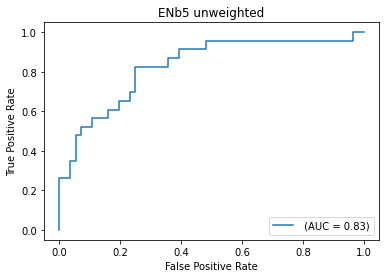

In [ ]:
y = llist.cpu().detach().numpy()
preds = outlist.cpu().detach().numpy()
fpr, tpr, thresholds = roc_curve(y, preds)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="")
display.plot()
plt.title("ENb5 unweighted")
plt.show()

In [ ]:
def imshow(img):
    img = img.cpu()
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [ ]:
model

EfficientNet(
  (_conv_stem): Conv2dStaticSamePadding(
    3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False
    (static_padding): ZeroPad2d(padding=(1, 1, 1, 1), value=0.0)
  )
  (_bn0): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
  (_blocks): ModuleList(
    (0): MBConvBlock(
      (_depthwise_conv): Conv2dStaticSamePadding(
        32, 32, kernel_size=(3, 3), stride=[1, 1], groups=32, bias=False
        (static_padding): ZeroPad2d(padding=(1, 1, 1, 1), value=0.0)
      )
      (_bn1): BatchNorm2d(32, eps=0.001, momentum=0.010000000000000009, affine=True, track_running_stats=True)
      (_se_reduce): Conv2dStaticSamePadding(
        32, 8, kernel_size=(1, 1), stride=(1, 1)
        (static_padding): Identity()
      )
      (_se_expand): Conv2dStaticSamePadding(
        8, 32, kernel_size=(1, 1), stride=(1, 1)
        (static_padding): Identity()
      )
      (_project_conv): Conv2dStaticSamePadding(
        32, 16, kernel_size=